In [1]:
!pip install google-search-results

from serpapi import GoogleSearch
import pandas as pd
import csv
import time

from getpass import getpass

api_key = getpass("Enter your SerpApi API key: ")

cities = ["Kochi","Kozhikode","Thrissur","Malappuram","Thiruvananthapuram","Kannur","Kollam","Ernakulam"]

print("Setup Completed!")


Defaulting to user installation because normal site-packages is not writeable


Enter your SerpApi API key:  ········


Setup Completed!


In [2]:
all_gyms = []
for city in cities:

  start_index = 0

  while True:
    params = {
    "engine": "google_maps",
    "q":f"gyms in {city}, Kerala",
    "api_key": api_key,
    "start":start_index}

    search = GoogleSearch(params)
    results = search.get_dict()

    if "error" in results:
      print(f"Error for {city}: {results['error']}")
      break

    gyms = results.get("local_results", [])

    for gym in gyms:
      gym["Search_City"] = city


    all_gyms.extend(gyms)

    print(city, "-", start_index, "-", len(gyms))


    if "next" not in results["serpapi_pagination"]:
      break
    start_index +=20









Kochi - 0 - 20
Kochi - 20 - 20
Kochi - 40 - 20
Kochi - 60 - 20
Kochi - 80 - 20
Kochi - 100 - 20
Kochi - 120 - 20
Kochi - 140 - 20
Kochi - 160 - 20
Kochi - 180 - 11
Kozhikode - 0 - 20
Kozhikode - 20 - 20
Kozhikode - 40 - 20
Kozhikode - 60 - 20
Kozhikode - 80 - 20
Kozhikode - 100 - 20
Kozhikode - 120 - 20
Kozhikode - 140 - 20
Kozhikode - 160 - 6
Thrissur - 0 - 20
Thrissur - 20 - 20
Thrissur - 40 - 20
Thrissur - 60 - 20
Thrissur - 80 - 20
Thrissur - 100 - 20
Thrissur - 120 - 20
Thrissur - 140 - 1
Malappuram - 0 - 20
Malappuram - 20 - 20
Malappuram - 40 - 20
Malappuram - 60 - 2
Thiruvananthapuram - 0 - 20
Thiruvananthapuram - 20 - 20
Thiruvananthapuram - 40 - 20
Thiruvananthapuram - 60 - 20
Thiruvananthapuram - 80 - 20
Thiruvananthapuram - 100 - 20
Thiruvananthapuram - 120 - 20
Thiruvananthapuram - 140 - 20
Thiruvananthapuram - 160 - 20
Thiruvananthapuram - 180 - 20
Error for Thiruvananthapuram: Google hasn't returned any results for this query.
Kannur - 0 - 20
Kannur - 20 - 20
Kannur - 40

In [3]:
df = pd.DataFrame(all_gyms)

print(df[["Search_City", "title", "address", "place_id"]].head())

  Search_City                   title  \
0       Kochi           Stark Fitness   
1       Kochi  Vc Fitness & Gym Kochi   
2       Kochi        Gold's Gym Kochi   
3       Kochi  Downtown fitness kochi   
4       Kochi         UNIT 45 FITNESS   

                                             address  \
0  Regional Sport Centre, Gandhinagar Rd, Kadavan...   
1  2nd Floor, Marian Enclave, Mahakavi Vailoppill...   
2  4th Syama Business Centre,Opp Hindu Office, NH...   
3  1st floor, Edatt building, Old Railway Station...   
4  Metro Piller No - 705, KPCC Junction, 2nd floo...   

                      place_id  
0  ChIJYWl1YslyCDsRYOVl1RD0ZHc  
1  ChIJMbiwIg8NCDsRIkaXdWwrWbo  
2  ChIJd7LFnioNCDsR7-tP3bOYQhM  
3  ChIJx9E8Na0NCDsRp0d1OQb-Bdg  
4  ChIJUeaiwZZzCDsR5zBaE3UdBho  


In [4]:
print("Total raw records:", len(all_gyms))

Total raw records: 1190


In [5]:
df = pd.DataFrame(all_gyms)

print("Duplicate by place_id:", df.duplicated(subset=["place_id"]).sum())

print("Duplicate by name + address:",
      df.duplicated(subset=["title", "address"]).sum())

df = df.drop_duplicates(subset=["place_id"])

print("Records after removing duplicates:", len(df))

Duplicate by place_id: 218
Duplicate by name + address: 218
Records after removing duplicates: 972


In [6]:
final_df = df[[
    "Search_City",
    "title",
    "phone",
    "address",
    "website",
    "rating",
    "reviews"
]]

In [7]:
final_df = final_df.rename(columns={
    "title": "Name",
    "phone": "Phone",
    "address": "Address",
    "website": "Website",
    "rating": "Rating",
    "reviews": "Reviews"
})

In [8]:
print(final_df.head())
print(final_df.shape)

  Search_City                    Name             Phone  \
0       Kochi           Stark Fitness   +91 97450 11000   
1       Kochi  Vc Fitness & Gym Kochi   +91 70255 52277   
2       Kochi        Gold's Gym Kochi  +91 484 415 1998   
3       Kochi  Downtown fitness kochi   +91 77366 40632   
4       Kochi         UNIT 45 FITNESS   +91 70250 33044   

                                             Address  \
0  Regional Sport Centre, Gandhinagar Rd, Kadavan...   
1  2nd Floor, Marian Enclave, Mahakavi Vailoppill...   
2  4th Syama Business Centre,Opp Hindu Office, NH...   
3  1st floor, Edatt building, Old Railway Station...   
4  Metro Piller No - 705, KPCC Junction, 2nd floo...   

                                             Website  Rating  Reviews  
0                      http://starkfitnesskochi.com/     4.9   1090.0  
1                                                NaN     4.9    611.0  
2  https://goldsgym.in/our-gyms/gold-s-gym-kochi-...     4.5    678.0  
3                   

In [9]:
print(final_df.isnull().sum())

Search_City      0
Name             0
Phone          167
Address          0
Website        620
Rating          16
Reviews         16
dtype: int64


In [10]:
final_df[final_df["Address"].isna()]

,Search_City,Name,Phone,Address,Website,Rating,Reviews


In [11]:
final_df = final_df.dropna(
    subset=["Address", "Phone", "Website"],
    how="all"
)

In [12]:
print(final_df.shape)
print(final_df.isnull().sum())

(972, 7)
Search_City      0
Name             0
Phone          167
Address          0
Website        620
Rating          16
Reviews         16
dtype: int64


In [13]:
final_df.to_csv("Kerala_Gyms.csv", index=False)

print("File created successfully!")
print(final_df.shape)

File created successfully!
(972, 7)


In [14]:
check_df = pd.read_csv("Kerala_Gyms.csv")

print(check_df.head())
print(check_df.shape)

  Search_City                    Name             Phone  \
0       Kochi           Stark Fitness   +91 97450 11000   
1       Kochi  Vc Fitness & Gym Kochi   +91 70255 52277   
2       Kochi        Gold's Gym Kochi  +91 484 415 1998   
3       Kochi  Downtown fitness kochi   +91 77366 40632   
4       Kochi         UNIT 45 FITNESS   +91 70250 33044   

                                             Address  \
0  Regional Sport Centre, Gandhinagar Rd, Kadavan...   
1  2nd Floor, Marian Enclave, Mahakavi Vailoppill...   
2  4th Syama Business Centre,Opp Hindu Office, NH...   
3  1st floor, Edatt building, Old Railway Station...   
4  Metro Piller No - 705, KPCC Junction, 2nd floo...   

                                             Website  Rating  Reviews  
0                      http://starkfitnesskochi.com/     4.9   1090.0  
1                                                NaN     4.9    611.0  
2  https://goldsgym.in/our-gyms/gold-s-gym-kochi-...     4.5    678.0  
3                   

In [15]:
city_counts = final_df.groupby("Search_City").size()

print(city_counts)

Search_City
Ernakulam              72
Kannur                100
Kochi                 176
Kollam                115
Kozhikode             154
Malappuram             60
Thiruvananthapuram    166
Thrissur              129
dtype: int64


In [16]:
city_counts = (
    final_df
    .groupby("Search_City")
    .size()
    .reset_index(name="Gym_Count")
)

print(city_counts)

          Search_City  Gym_Count
0           Ernakulam         72
1              Kannur        100
2               Kochi        176
3              Kollam        115
4           Kozhikode        154
5          Malappuram         60
6  Thiruvananthapuram        166
7            Thrissur        129


In [17]:
avg_rating = (
    final_df
    .groupby("Search_City")["Rating"]
    .mean()
    .reset_index(name="Average_Rating")
)

print(avg_rating)

          Search_City  Average_Rating
0           Ernakulam        4.702778
1              Kannur        4.679787
2               Kochi        4.731818
3              Kollam        4.800893
4           Kozhikode        4.643709
5          Malappuram        4.773333
6  Thiruvananthapuram        4.770909
7            Thrissur        4.714286


In [18]:
city_summary = city_counts.merge(
    avg_rating,
    on="Search_City"
)

print(city_summary)

          Search_City  Gym_Count  Average_Rating
0           Ernakulam         72        4.702778
1              Kannur        100        4.679787
2               Kochi        176        4.731818
3              Kollam        115        4.800893
4           Kozhikode        154        4.643709
5          Malappuram         60        4.773333
6  Thiruvananthapuram        166        4.770909
7            Thrissur        129        4.714286


In [19]:
total_reviews = (
    final_df
    .groupby("Search_City")["Reviews"]
    .sum()
    .reset_index(name="Total_Reviews")
)

print(total_reviews)

          Search_City  Total_Reviews
0           Ernakulam         9812.0
1              Kannur        22141.0
2               Kochi        30140.0
3              Kollam        14607.0
4           Kozhikode        25091.0
5          Malappuram         5176.0
6  Thiruvananthapuram        38921.0
7            Thrissur        15954.0


In [20]:
city_summary = city_summary.merge(
    total_reviews,
    on="Search_City"
)

print(city_summary)

          Search_City  Gym_Count  Average_Rating  Total_Reviews
0           Ernakulam         72        4.702778         9812.0
1              Kannur        100        4.679787        22141.0
2               Kochi        176        4.731818        30140.0
3              Kollam        115        4.800893        14607.0
4           Kozhikode        154        4.643709        25091.0
5          Malappuram         60        4.773333         5176.0
6  Thiruvananthapuram        166        4.770909        38921.0
7            Thrissur        129        4.714286        15954.0


In [21]:
city_summary["Avg_Reviews_Per_Gym"] = (
    city_summary["Total_Reviews"] / city_summary["Gym_Count"]
)

print(city_summary)

          Search_City  Gym_Count  Average_Rating  Total_Reviews  \
0           Ernakulam         72        4.702778         9812.0   
1              Kannur        100        4.679787        22141.0   
2               Kochi        176        4.731818        30140.0   
3              Kollam        115        4.800893        14607.0   
4           Kozhikode        154        4.643709        25091.0   
5          Malappuram         60        4.773333         5176.0   
6  Thiruvananthapuram        166        4.770909        38921.0   
7            Thrissur        129        4.714286        15954.0   

   Avg_Reviews_Per_Gym  
0           136.277778  
1           221.410000  
2           171.250000  
3           127.017391  
4           162.928571  
5            86.266667  
6           234.463855  
7           123.674419  


In [22]:
city_summary["Average_Rating"] = city_summary["Average_Rating"].round(2)

city_summary["Avg_Reviews_Per_Gym"] = (
    city_summary["Avg_Reviews_Per_Gym"].round(1)
)

city_summary["Total_Reviews"] = city_summary["Total_Reviews"].astype(int)

print(city_summary)

          Search_City  Gym_Count  Average_Rating  Total_Reviews  \
0           Ernakulam         72            4.70           9812   
1              Kannur        100            4.68          22141   
2               Kochi        176            4.73          30140   
3              Kollam        115            4.80          14607   
4           Kozhikode        154            4.64          25091   
5          Malappuram         60            4.77           5176   
6  Thiruvananthapuram        166            4.77          38921   
7            Thrissur        129            4.71          15954   

   Avg_Reviews_Per_Gym  
0                136.3  
1                221.4  
2                171.2  
3                127.0  
4                162.9  
5                 86.3  
6                234.5  
7                123.7  


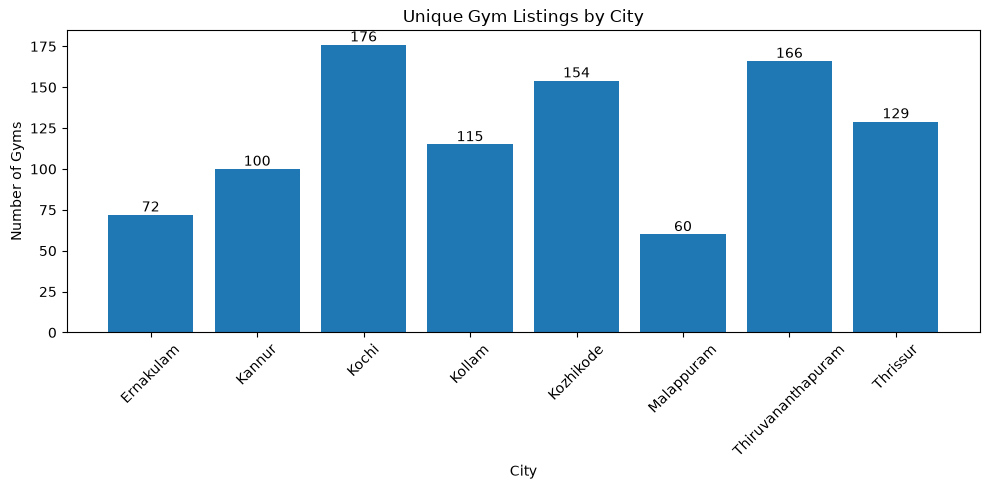

In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

bars = plt.bar(
    city_summary["Search_City"],
    city_summary["Gym_Count"]
)

plt.xlabel("City")
plt.ylabel("Number of Gyms")
plt.title("Unique Gym Listings by City")

plt.xticks(rotation=45)

# Add values on top of bars
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        int(height),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

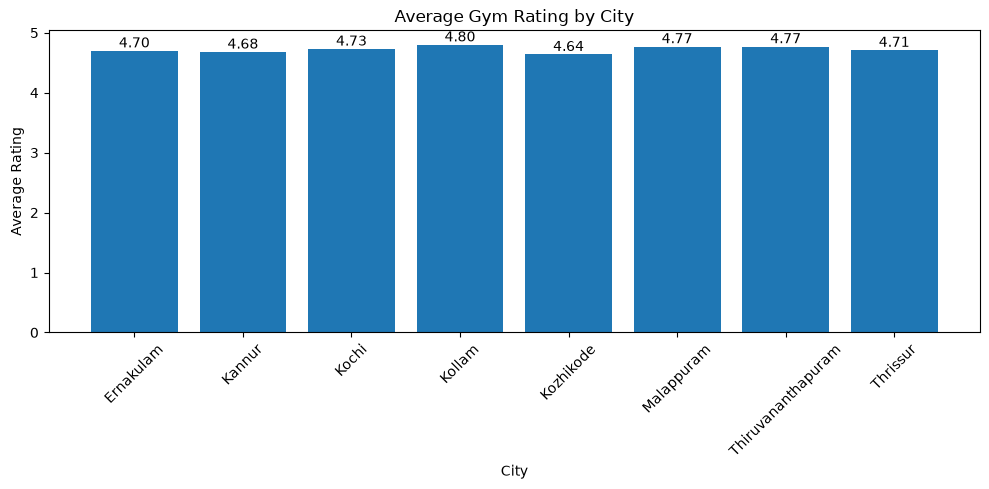

In [24]:
plt.figure(figsize=(10, 5))

bars = plt.bar(
    city_summary["Search_City"],
    city_summary["Average_Rating"]
)

plt.xlabel("City")
plt.ylabel("Average Rating")
plt.title("Average Gym Rating by City")

plt.xticks(rotation=45)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.2f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [25]:
top_gyms = (
    final_df
    .sort_values("Reviews", ascending=False)
    .head(10)
)

print(
    top_gyms[
        ["Search_City", "Name", "Rating", "Reviews"]
    ]
)

             Search_City                                 Name  Rating  Reviews
867               Kannur                         Capitol Mall     4.0  10982.0
755   Thiruvananthapuram        Decathlon Sports - Trivandrum     4.6   4967.0
344            Kozhikode     Hotel Yash International Calicut     4.5   4727.0
757   Thiruvananthapuram          Jimmy George Indoor Stadium     4.4   3052.0
191            Kozhikode              The Belly Gym (Calicut)     4.9   2600.0
1001              Kollam            Decathlon Sports - Kollam     4.9   2359.0
852               Kannur                        Cosmos Sports     4.7   2310.0
560   Thiruvananthapuram                 Jones Gym Trivandrum     4.9   1759.0
566   Thiruvananthapuram                     Tiger Gym Pattom     4.9   1247.0
762               Kannur  Bilitary Gym & Fitness (Powers Inn)     4.9   1133.0


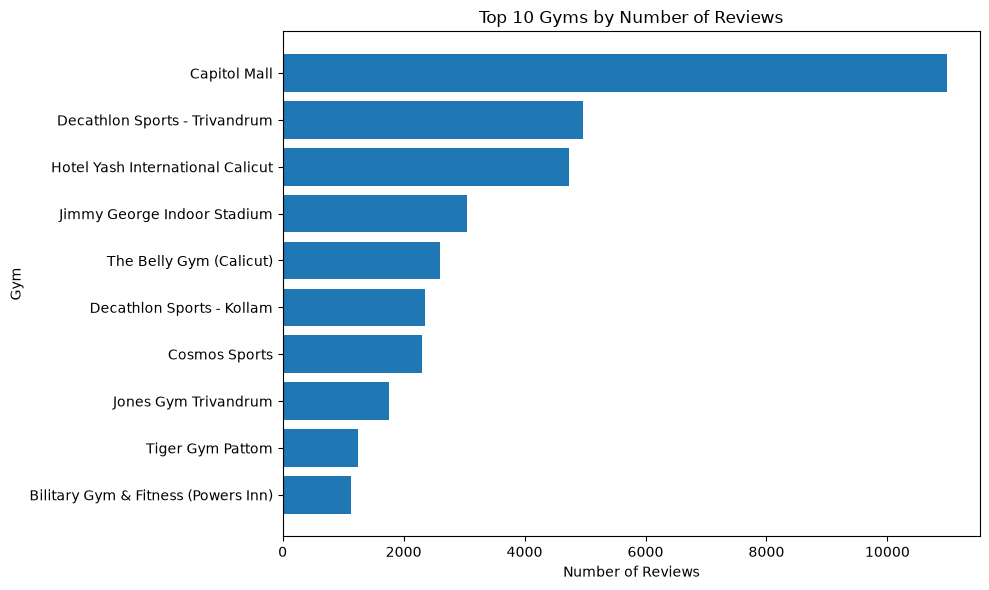

In [26]:
plt.figure(figsize=(10, 6))

bars = plt.barh(
    top_gyms["Name"],
    top_gyms["Reviews"]
)

plt.xlabel("Number of Reviews")
plt.ylabel("Gym")
plt.title("Top 10 Gyms by Number of Reviews")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()